# Extension - calibration, cost-based cutoff, temporal and hotel transfer

**Question.** Can the probabilities be used for decisions, and would the model hold up later or at another hotel?

**Brief and report.** Part H (robustness and deployment). Report Sections 8.3–8.4.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

`decision_validation()` in `src/decision.py` does three checks:
1. **Calibration and cutoffs.** The training rows' out-of-fold predictions are split three ways: to fit Platt calibration, to choose cost-based cutoffs, and to check them.
2. **Over time.** Train on arrivals before 2017 and test on later bookings.
3. **Between hotels.** Train on one hotel and test on the other.

**How to read the output.** `policy` gives the cost per 1,000 bookings for each assumed cost ratio. `temporal` and `transfer` show how far AP drops outside the random split.

In [2]:
from src.decision import decision_validation
policy, temporal, transfer = decision_validation()
display(policy)
display(temporal)
display(transfer)
display(results('d2_5_temporal_drift.csv'))

Decision check | policy frozen: Voting: sigmoid calibration; 5:1 cutoff 0.18


Decision check | temporal: Logistic Regression (default): later-period AP 0.552


Decision check | temporal: Random Forest (default): later-period AP 0.533


Decision check | temporal: Hist Gradient Boosting (default): later-period AP 0.553


Decision check | temporal: Logistic Regression (tuned): later-period AP 0.552


Decision check | temporal: Random Forest (tuned): later-period AP 0.537


... (2 outputs left out)

,scope,ratio,option,threshold,rows,cost_per_1000,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,brier
0,training_policy_validation,1,raw at 0.5,0.50,17470,191.872,0.808,0.712,0.722,0.496,0.588,0.836,0.693,0.137
1,training_policy_validation,1,calibrated at 0.5,0.50,17470,191.986,0.808,0.713,0.718,0.501,0.590,0.836,0.693,0.137
2,training_policy_validation,1,chosen cutoff,0.54,17470,192.673,0.807,0.703,0.736,0.471,0.574,0.836,0.693,0.137
3,training_policy_validation,2,raw at 0.5,0.50,17470,330.967,0.808,0.712,0.722,0.496,0.588,0.836,0.693,0.137
4,training_policy_validation,2,calibrated at 0.5,0.50,17470,329.594,0.808,0.713,0.718,0.501,0.590,0.836,0.693,0.137
5,training_policy_validation,2,chosen cutoff,0.32,17470,301.259,0.786,0.754,0.599,0.683,0.638,0.836,0.693,0.137
6,training_policy_validation,5,raw at 0.5,0.50,17470,748.254,0.808,0.712,0.722,0.496,0.588,0.836,0.693,0.137
7,training_policy_validation,5,calibrated at 0.5,0.50,17470,742.416,0.808,0.713,0.718,0.501,0.590,0.836,0.693,0.137
8,training_policy_validation,5,chosen cutoff,0.18,17470,479.222,0.688,0.738,0.465,0.848,0.600,0.836,0.693,0.137
9,training_policy_validation,10,raw at 0.5,0.50,17470,1443.732,0.808,0.712,0.722,0.496,0.588,0.836,0.693,0.137


,model,training_rows,validation_rows,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,brier
0,Logistic Regression (default),44492,18468,0.768,0.643,0.646,0.362,0.464,0.764,0.552,0.164
1,Random Forest (default),44492,18468,0.762,0.642,0.616,0.375,0.466,0.753,0.533,0.169
2,Hist Gradient Boosting (default),44492,18468,0.768,0.654,0.629,0.398,0.488,0.779,0.553,0.165
3,Logistic Regression (tuned),44492,18468,0.768,0.645,0.644,0.368,0.468,0.764,0.552,0.164
4,Random Forest (tuned),44492,18468,0.765,0.648,0.623,0.385,0.476,0.756,0.537,0.169
5,Hist Gradient Boosting (tuned),44492,18468,0.765,0.652,0.621,0.397,0.485,0.773,0.552,0.168
6,Voting (tuned),44492,18468,0.766,0.651,0.625,0.392,0.482,0.768,0.548,0.167


,model,training_hotel,validation_hotel,training_rows,validation_rows,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,brier
0,Voting,City Hotel,Resort Hotel,42768,27109,0.772,0.535,0.610,0.086,0.151,0.691,0.425,0.165
1,Voting,Resort Hotel,City Hotel,27109,42768,0.730,0.564,0.782,0.145,0.244,0.739,0.579,0.186


,feature,earlier_median,later_median,ks_statistic,p_value,p_holm
0,lead_time,43.0,36.0,0.069,1.092e-54,4.370e-54
1,adr,92.0,120.0,0.226,0.000e+00,0.000e+00
2,adults,2.0,2.0,0.021,1.275e-05,2.550e-05
3,total_of_special_requests,0.0,1.0,0.044,2.817e-22,8.452e-22
4,previous_cancellations,0.0,0.0,0.013,1.778e-02,1.778e-02


The figures show the reliability diagram (do predicted probabilities match observed rates?), the cost at each cost ratio, and AP on the later period.

**reports/figures/fig_H_10_calibration_test_set.png**

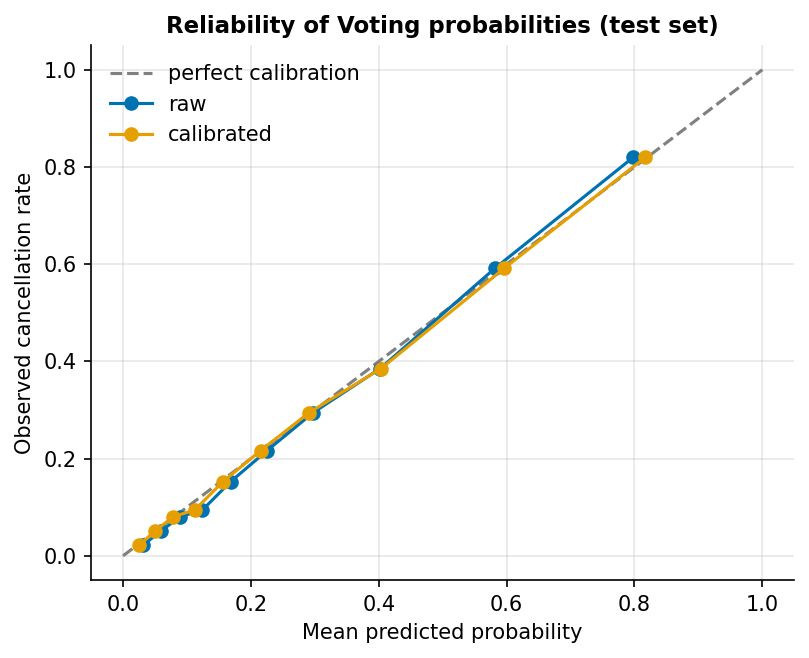

**reports/figures/fig_H_11_cost_sensitivity.png**

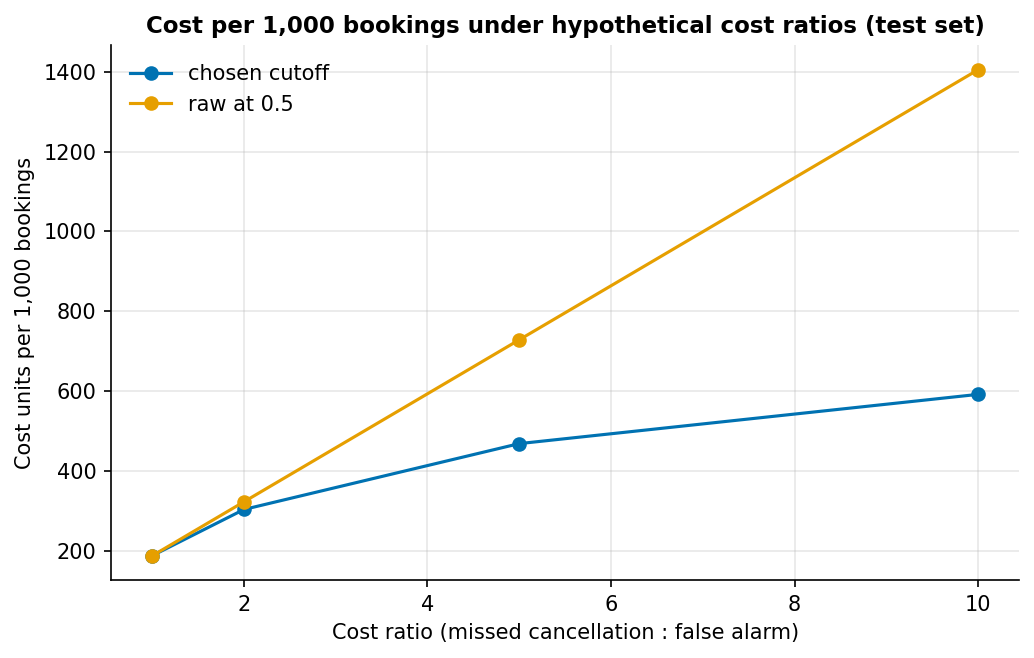

**reports/figures/fig_H_14_temporal.png**

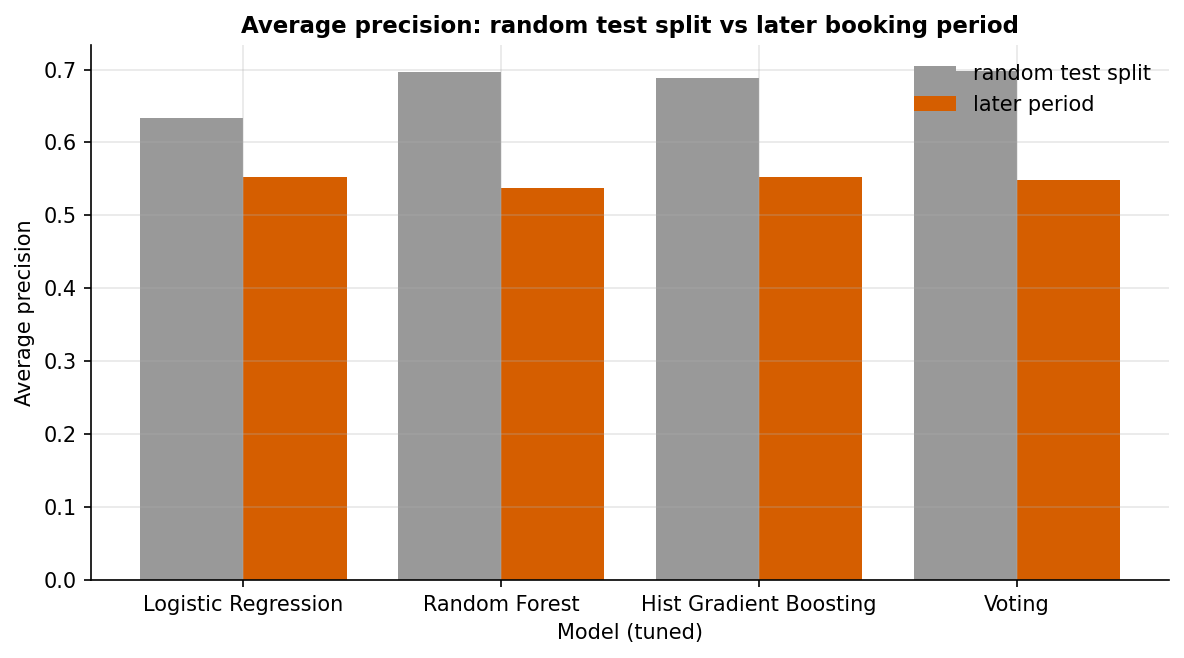

In [3]:
show('fig_H_10_calibration_test_set.png', 'fig_H_11_cost_sensitivity.png', 'fig_H_14_temporal.png')